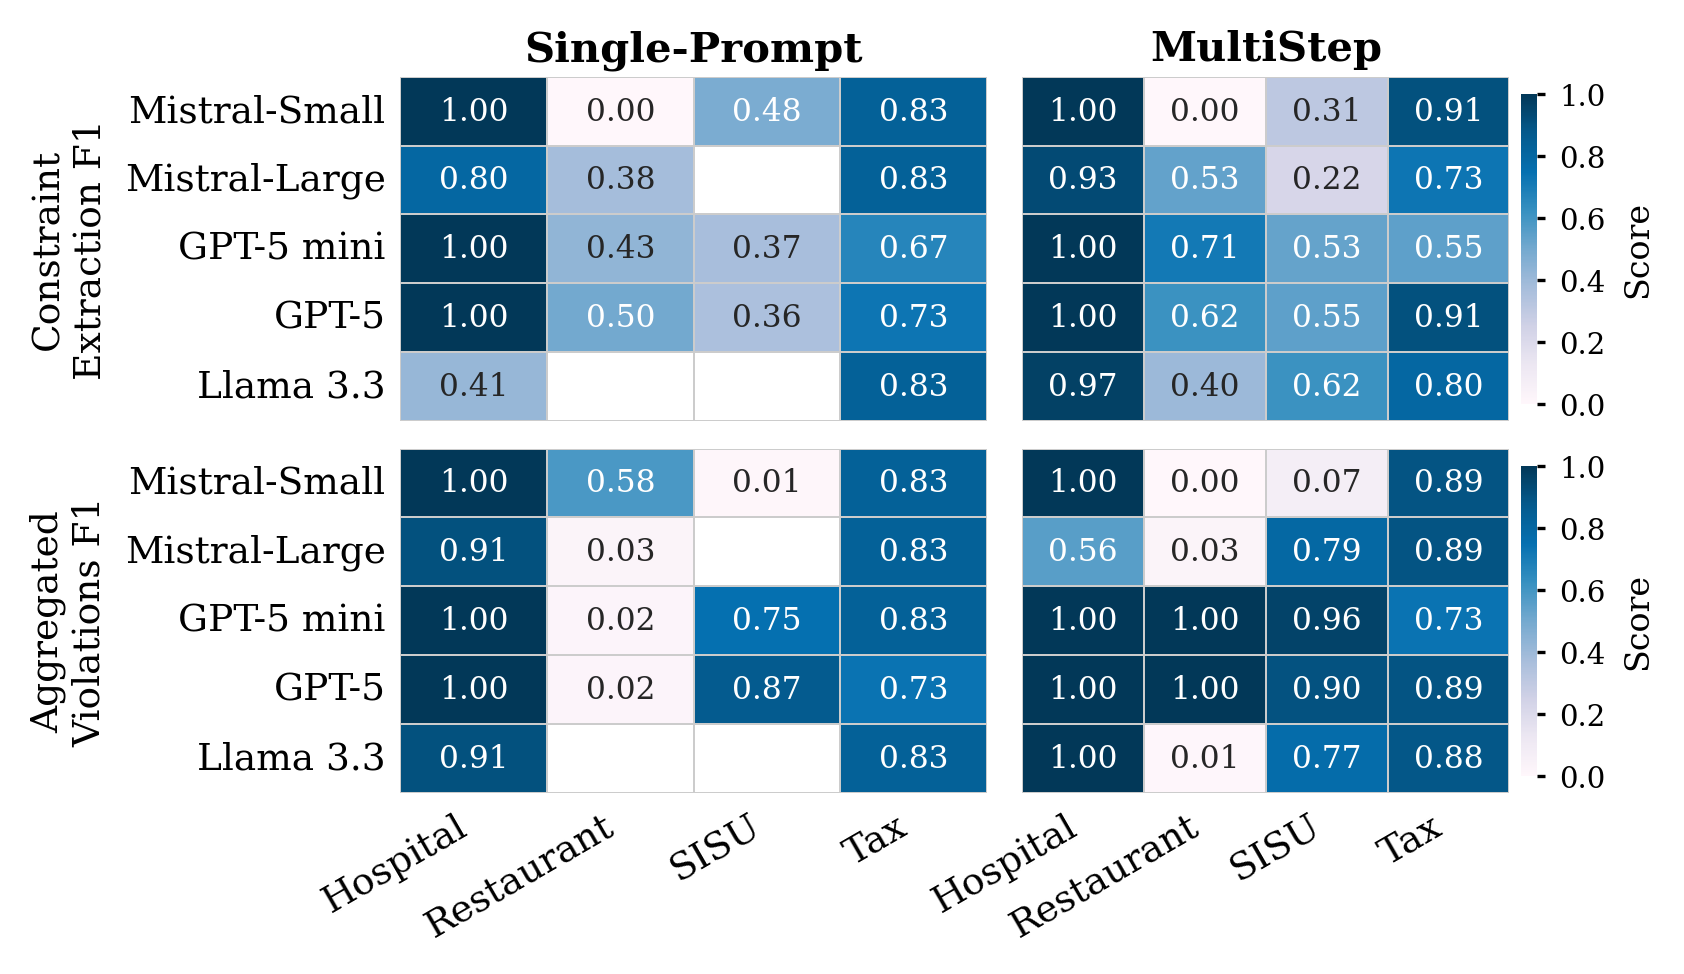

Saved heatmap to `best_mapping.pdf` and `best_mapping.png`

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

# ── Publication style ──────────────────────────────────────────────────────────
mpl.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.titlesize":    10,
    "axes.labelsize":    9,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "figure.dpi":        300,
    "savefig.dpi":       300,
    "savefig.bbox":      "tight",
    "text.usetex":       False,   # set True if LaTeX is available
    "axes.linewidth":    0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

main_metrics = ["constraint_exact_f1", "agg_viol_f1"]
metric_labels = {
    "constraint_exact_f1": "Constraint\nExtraction F1",
    "agg_viol_f1":         "Aggregated\nViolations F1",
}

# ColorBrewer YlOrRd — prints well in grayscale
cmap = "YlOrRd"
cmap = "Set2"
cmap = "crest"
cmap = "mako"
cmap = "rocket_r"
cmap = "YlGnBu"
cmap = "PuBu"






# Ordered model / dataset display lists (depend on cell 1 variables)
ordered_models   = [model_display[m]   for m in models   if m in model_display]
ordered_datasets = [dataset_display[d] for d in datasets if d in dataset_display]

n_impl    = len(IMPLEMENTATION_ORDER)
n_metrics = len(main_metrics)

# ── Grid: rows = metrics, cols = implementations ───────────────────────────────
fig, axes = plt.subplots(
    n_metrics, n_impl,
    figsize=(2.6 * n_impl, 1.55 * n_metrics),
    gridspec_kw={"hspace": 0.08, "wspace": 0.06},
)

# Guarantee 2-D indexing
if n_metrics == 1:
    axes = [axes]
if n_impl == 1:
    axes = [[row] for row in axes]

def _fmt(v):
    return f"{v:.2f}" if not pd.isna(v) else "—"

for row_idx, metric in enumerate(main_metrics):
    for col_idx, impl in enumerate(IMPLEMENTATION_ORDER):
        ax = axes[row_idx][col_idx]

        df_impl = df[df["implementation_canonical"] == impl].copy()
        df_impl["model_d"]   = df_impl["model"].map(model_display)
        df_impl["dataset_d"] = df_impl["dataset"].map(dataset_display)

        heat_data = (
            df_impl.groupby(["model_d", "dataset_d"])[metric]
            .mean()
            .unstack("dataset_d")
            .reindex(index=ordered_models, columns=ordered_datasets)
        )

        annot = heat_data.apply(lambda col: col.map(_fmt))

        show_xticklabels = (row_idx == n_metrics - 1)
        show_yticklabels = (col_idx == 0)
        show_cbar        = (col_idx == n_impl - 1)

        sns.heatmap(
            heat_data,
            ax=ax,
            annot=annot,
            fmt="",
            cmap=cmap,
            vmin=0.0,
            vmax=1.0,
            linewidths=0.4,
            linecolor="#cccccc",
            cbar=show_cbar,
            cbar_kws={"shrink": 0.9, "label": "Score", "pad": 0.02},
            xticklabels=show_xticklabels,
            yticklabels=show_yticklabels,
            annot_kws={"size": 7.5},
        )

        # Implementation name as column title (top row only)
        if row_idx == 0:
            ax.set_title(IMPLEMENTATION_DISPLAY.get(impl, impl), fontweight="bold", pad=4)

        # Metric label on leftmost column only
        if show_yticklabels:
            ax.set_ylabel(metric_labels[metric], labelpad=4)
        else:
            ax.set_ylabel("")

        ax.set_xlabel("")

        # Rotate x-tick labels on bottom row only
        if show_xticklabels:
            ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")

        # Keep y-tick labels horizontal on leftmost column
        if show_yticklabels:
            ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

        ax.tick_params(length=0)

        if show_cbar:
            cbar = ax.collections[0].colorbar
            cbar.ax.tick_params(labelsize=7, length=2)
            cbar.set_label("Score", size=8)

plt.savefig("best_mapping.pdf", format="pdf")
plt.savefig("best_mapping.png", format="png")
plt.show()
display(Markdown("Saved heatmap to `best_mapping.pdf` and `best_mapping.png`"))
